# Buscador de conocimiento

**Dominio:** Buscador de conocimiento  
**Propósito:** mostrar un método breve para comparar configuraciones.

## Proyecto seleccionado

### Buscador de conocimiento

Encuentra información relevante en investigaciones, políticas o documentación interna.

### Objetivo

Recuperar contenido por significado y entregar resultados pertinentes con referencia al documento de origen.

## Resultado observable

Al terminar, el grupo habrá visto cómo:

1. tokenizar y comparar dos frases;
2. interpretar candidatos para el siguiente token;
3. construir un contexto mínimo;
4. ejecutar la misma pregunta con tres temperaturas;
5. registrar tokens, latencia y respuesta;
6. justificar una configuración inicial.

In [1]:
# 0. Preparación del entorno (ejecutar antes de la clase)
%pip install -q openai tiktoken pandas matplotlib ollama

import math
import os
import time
from getpass import getpass

import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
from openai import OpenAI

pd.set_option("display.max_colwidth", 100)
print("Entorno preparado.")

Entorno preparado.


## 1. Tokenizar y comparar

- Un token es la unidad que procesa el modelo.
- Un token no equivale necesariamente a una palabra.
- Tildes, signos, espacios y palabras pueden cambiar el conteo.
- Cada modelo puede utilizar un tokenizador diferente.
- Usaremos `tiktoken` como referencia para comparar el texto.

In [2]:
# Paso 1 y 2: tokenizar dos frases y comparar conteos

encoding = tiktoken.get_encoding("o200k_base")

frases = {
    "ES": "La política de seguridad establece el cambio de contraseña.",
    "EN": "The security policy establishes the password change.",
}

filas_tokens = []

for idioma, texto in frases.items():
    ids = encoding.encode(texto)
    piezas = [
        encoding.decode([token_id])
        for token_id in ids
    ]

    filas_tokens.append({
        "idioma": idioma,
        "texto": texto,
        "palabras_aprox": len(texto.split()),
        "tokens": len(ids),
        "piezas": piezas,
        "ids": ids,
    })

comparacion_tokens = pd.DataFrame(filas_tokens)

display(
    comparacion_tokens[
        [
            "idioma",
            "texto",
            "palabras_aprox",
            "tokens",
            "piezas"
        ]
    ]
)

,idioma,texto,palabras_aprox,tokens,piezas
0,ES,La política de seguridad establece el cambio de contraseña.,9,10,"[La, política, de, seguridad, establece, el, cambio, de, contraseña, .]"
1,EN,The security policy establishes the password change.,7,8,"[The, security, policy, establishes, the, password, change, .]"


## 2. Candidatos del siguiente token

1. El modelo calcula probabilidades para diferentes tokens candidatos.
2. `softmax` convierte las puntuaciones en probabilidades.
3. La temperatura modifica la distribución.
4. Una temperatura mayor permite mayor variedad, pero no agrega conocimiento.
5. `top_p` limita los candidatos considerados por el modelo.

temperatura,0.2,0.7,1.2
candidato,,,
documento,0.1 %,7.8 %,14.6 %
manual,2.9 %,24.3 %,28.3 %
otro,0.0 %,1.9 %,6.3 %
política,97.0 %,66.1 %,50.8 %


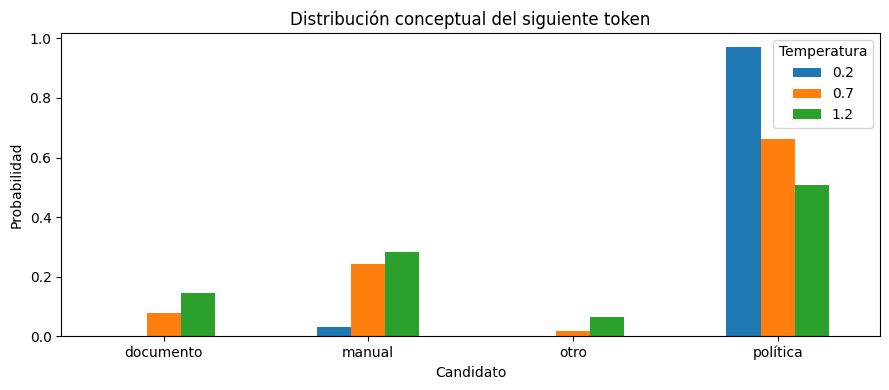

In [3]:
# Paso 3: visualizar candidatos y el efecto conceptual de la temperatura

candidatos = [
    "política",
    "manual",
    "documento",
    "otro"
]

logits = [3.2, 2.5, 1.7, 0.7]


def softmax_con_temperatura(valores, temperatura):
    temperatura_segura = max(temperatura, 0.01)

    escalados = [
        valor / temperatura_segura
        for valor in valores
    ]

    maximo = max(escalados)

    exponentes = [
        math.exp(valor - maximo)
        for valor in escalados
    ]

    total = sum(exponentes)

    return [
        valor / total
        for valor in exponentes
    ]


resultados_probabilidad = []

for temperatura in [0.2, 0.7, 1.2]:

    probabilidades = softmax_con_temperatura(
        logits,
        temperatura
    )

    for candidato, probabilidad in zip(
        candidatos,
        probabilidades
    ):

        resultados_probabilidad.append({
            "temperatura": temperatura,
            "candidato": candidato,
            "probabilidad": probabilidad,
        })


probabilidades_df = pd.DataFrame(
    resultados_probabilidad
)

pivote = probabilidades_df.pivot(
    index="candidato",
    columns="temperatura",
    values="probabilidad"
)

display(
    (pivote * 100)
    .round(1)
    .astype(str) + " %"
)

pivote.plot(
    kind="bar",
    figsize=(9, 4)
)

plt.title(
    "Distribución conceptual del siguiente token"
)

plt.ylabel("Probabilidad")
plt.xlabel("Candidato")
plt.xticks(rotation=0)
plt.legend(title="Temperatura")
plt.tight_layout()
plt.show()

## 3. Construir un contexto mínimo

- El contexto incluye la instrucción, los documentos disponibles y la pregunta.
- Un contexto más grande no significa necesariamente una mejor respuesta.
- La información irrelevante puede distraer al modelo.
- El modelo debe utilizar únicamente la información proporcionada.
- Si no encuentra evidencia suficiente, debe indicarlo.

**Pregunta antes de ejecutar:** ¿qué debería responder si se pregunta por un procedimiento que no aparece en los documentos?

**Respuesta esperada:** debe indicar que no existe información suficiente y no inventar una respuesta.

In [4]:
# Paso 4: contexto mínimo, una pregunta y conteo previo

instruccion = """Eres el asistente de un Buscador de Conocimiento.

Responde únicamente con la información proporcionada en los documentos.

Si falta información, dilo claramente.

Indica el documento de origen cuando sea posible.

No inventes información.

Responde en máximo 45 palabras."""


documentos = """DOCUMENTOS DISPONIBLES

Documento: Política de Seguridad de la Información
Contenido: Los usuarios deben cambiar su contraseña cada 90 días y utilizar una contraseña segura.

Documento: Manual de Trabajo Remoto
Contenido: El trabajo remoto requiere autorización previa del líder del equipo y conexión segura a los sistemas internos.

Documento: Guía de Gestión de Proyectos
Contenido: Los avances de los proyectos deben registrarse semanalmente en la herramienta de seguimiento."""


pregunta = "¿Cada cuánto tiempo se debe cambiar la contraseña?"


messages = [
    {
        "role": "system",
        "content": instruccion
    },
    {
        "role": "user",
        "content": f"{documentos}\n\nPREGUNTA: {pregunta}"
    },
]


texto_contexto = "\n".join(
    mensaje["content"]
    for mensaje in messages
)


tokens_contexto_estimados = len(
    encoding.encode(texto_contexto)
)


print(texto_contexto)

print(
    f"\nEstimación de referencia "
    f"(tokenizador de OpenAI): "
    f"{tokens_contexto_estimados} tokens"
)

print(
    "El conteo real del modelo local aparecerá "
    "en la columna tokens_entrada del paso 5."
)

Eres el asistente de un Buscador de Conocimiento.

Responde únicamente con la información proporcionada en los documentos.

Si falta información, dilo claramente.

Indica el documento de origen cuando sea posible.

No inventes información.

Responde en máximo 45 palabras.
DOCUMENTOS DISPONIBLES

Documento: Política de Seguridad de la Información
Contenido: Los usuarios deben cambiar su contraseña cada 90 días y utilizar una contraseña segura.

Documento: Manual de Trabajo Remoto
Contenido: El trabajo remoto requiere autorización previa del líder del equipo y conexión segura a los sistemas internos.

Documento: Guía de Gestión de Proyectos
Contenido: Los avances de los proyectos deben registrarse semanalmente en la herramienta de seguimiento.

PREGUNTA: ¿Cada cuánto tiempo se debe cambiar la contraseña?

Estimación de referencia (tokenizador de OpenAI): 161 tokens
El conteo real del modelo local aparecerá en la columna tokens_entrada del paso 5.


## 4. Conectar el modelo

- El nombre del modelo, el servidor y los parámetros forman parte de la configuración.
- Ollama permite ejecutar el modelo localmente.
- El modelo reportará información sobre tokens y tiempos.
- El conteo realizado con `tiktoken` es solamente una referencia.

In [5]:
!apt-get install -y zstd
!zstd --version

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 57 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 1s (1,028 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122579 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
*** zstd command line interface 64-bits v1.4.8, by Yann Collet ***


In [6]:
# Instalar Ollama en la sesión de Colab
!sudo apt-get install -y -q pciutils
!curl -fsSL https://ollama.com/install.sh | sh

# La instalación debe reportar "NVIDIA GPU installed". Si no aparece, revise el entorno de ejecución.
!nvidia-smi --query-gpu=name,memory.total --format=csv

Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  libpci3 pci.ids
The following NEW packages will be installed:
  libpci3 pci.ids pciutils
0 upgraded, 3 newly installed, 0 to remove and 57 not upgraded.
Need to get 343 kB of archives.
After this operation, 1,581 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 pci.ids all 0.0~2022.01.22-1ubuntu0.1 [251 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/main amd64 libpci3 amd64 1:3.7.0-6 [28.9 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/main amd64 pciutils amd64 1:3.7.0-6 [63.6 kB]
Fetched 343 kB in 2s (219 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 3.)
debconf: falling back to frontend: Readline
debconf: unable to initial

In [7]:
import subprocess
import time
import ollama

In [8]:
# Iniciar el servidor local y descargar el modelo
# Verifique el nombre en https://ollama.com/library antes de clase.
MODEL_NAME = "gemma4:e2b"

subprocess.Popen(["ollama", "serve"])
time.sleep(10)

!ollama pull {MODEL_NAME}

In [9]:
# Respuesta de prueba: confirma que el modelo responde

prueba = ollama.chat(
    model=MODEL_NAME,
    messages=messages,
    think=False,
    options={
        "temperature": 0.2,
        "num_predict": 300
    },
)

print(
    prueba["message"]["content"]
)

print(
    "thinking:",
    prueba["message"].get("thinking")
)

Los usuarios deben cambiar su contraseña cada 90 días y utilizar una contraseña segura. (Política de Seguridad de la Información)
thinking: None


In [10]:
# El modelo debe aparecer con PROCESSOR = 100% GPU.
!ollama ps

NAME          ID              SIZE      PROCESSOR    CONTEXT    UNTIL              
gemma4:e2b    7fbdbf8f5e45    1.7 GB    100% GPU     4096       4 minutes from now    


## 5. Ejecutar tres configuraciones

Se mantiene constante:

- el modelo;
- la instrucción;
- los documentos;
- la pregunta;
- `top_p = 1.0`;
- el límite de salida.

Solo cambia la temperatura:

- `0.0`
- `0.7`
- `1.2`

El objetivo es observar cómo cambia la respuesta del buscador y verificar que siga siendo fiel a los documentos.

In [14]:
# Paso 5 y 6: generar con tres temperaturas y registrar tokens + latencia

NANOSEGUNDOS = 1_000_000_000


def ejecutar_prueba(
    temperatura,
    top_p=1.0,
    num_predict=300
):

    inicio = time.perf_counter()

    respuesta = ollama.chat(
        model=MODEL_NAME,
        messages=messages,
        options={
            "temperature": temperatura,
            "top_p": top_p,
            "num_predict": num_predict,
        },
    )

    latencia = (
        time.perf_counter() - inicio
    )

    tokens_entrada = respuesta.get(
        "prompt_eval_count"
    )

    tokens_salida = respuesta.get(
        "eval_count"
    )

    carga = respuesta.get(
        "load_duration",
        0
    ) / NANOSEGUNDOS

    return {
        "temperatura": temperatura,
        "top_p": top_p,
        "num_predict": num_predict,
        "tokens_entrada": tokens_entrada,
        "tokens_salida": tokens_salida,
        "tokens_total": (
            (tokens_entrada or 0)
            + (tokens_salida or 0)
        ),
        "latencia_s": round(
            latencia,
            2
        ),
        "carga_s": round(
            carga,
            2
        ),
        "respuesta": respuesta[
            "message"
        ]["content"].strip(),
    }


resultados = []

for temperatura in [0.0, 2, 3]:

    print(
        f"Ejecutando temperatura={temperatura}..."
    )

    resultados.append(
        ejecutar_prueba(
            temperatura=temperatura
        )
    )


resultados_df = pd.DataFrame(
    resultados
)

display(resultados_df)


print(
    f"Tokens estimados con tiktoken: "
    f"{tokens_contexto_estimados} | "
    f"Tokens reportados por {MODEL_NAME}: "
    f"{resultados_df['tokens_entrada'].iloc[0]}"
)

Ejecutando temperatura=0.0...
Ejecutando temperatura=2...
Ejecutando temperatura=3...


,temperatura,top_p,num_predict,tokens_entrada,tokens_salida,tokens_total,latencia_s,carga_s,respuesta
0,0.0,1.0,300,190,258,448,3.04,0.0,Los usuarios deben cambiar su contraseña cada 90 días. (Política de Seguridad de la Información)
1,2.0,1.0,300,190,263,453,2.97,0.0,Los usuarios deben cambiar su contraseña cada 90 días. (Política de Seguridad de la Información)
2,3.0,1.0,300,190,250,440,2.83,0.0,"Deben cambiar su contraseña cada 90 días, como establece la Política de Seguridad de la Informac..."


Tokens estimados con tiktoken: 161 | Tokens reportados por gemma4:e2b: 190


In [16]:
# Mostramos las respuestas de cada temperatura

for r in resultados:

    print(
        r["temperatura"],
        "->",
        repr(r["respuesta"])[:300]
    )

0.0 -> 'Los usuarios deben cambiar su contraseña cada 90 días. (Política de Seguridad de la Información)'
2 -> 'Los usuarios deben cambiar su contraseña cada 90 días. (Política de Seguridad de la Información)'
3 -> 'Deben cambiar su contraseña cada 90 días, como establece la Política de Seguridad de la Información.\n(Documento: Política de Seguridad de la Información)'


## 5.1 Lectura guiada de la tabla

1. **Validez factual:** comprobar que la respuesta coincida con los documentos.
2. **Pertinencia:** verificar que responda la pregunta realizada.
3. **Fuente:** comprobar que mencione el documento de origen.
4. **No alucinación:** verificar que no invente información.
5. **Estabilidad:** comparar las respuestas entre temperaturas.
6. **Eficiencia:** observar tokens de salida y latencia.
7. **Contexto:** analizar si la información proporcionada fue suficiente y relevante.

In [13]:
# Resumen para analizar y copiar a la bitácora

resumen = resultados_df[
    [
        "temperatura",
        "tokens_entrada",
        "tokens_salida",
        "latencia_s",
        "carga_s",
        "respuesta"
    ]
].copy()

resumen["cumple_evidencia"] = "REVISAR"

resumen["documento_origen"] = "REVISAR"

resumen["decision"] = (
    "CONSERVAR / DESCARTAR"
)

display(resumen)


print("\nDECISIÓN PARA LA BITÁCORA")

print(
    "Conservamos temperatura = ____ "
    "porque ________________________________."
)

print(
    "Observamos como limitación "
    "__________________________________________."
)

print(
    "En la siguiente prueba cambiaremos "
    "únicamente ______________________________."
)

,temperatura,tokens_entrada,tokens_salida,latencia_s,carga_s,respuesta,cumple_evidencia,documento_origen,decision
0,0.0,190,266,3.03,0.0,Los usuarios deben cambiar su contraseña cada 90 días. (Documento: Política de Seguridad de la I...,REVISAR,REVISAR,CONSERVAR / DESCARTAR
1,0.7,190,284,3.21,0.0,"Los usuarios deben cambiar su contraseña cada 90 días, según la Política de Seguridad de la Info...",REVISAR,REVISAR,CONSERVAR / DESCARTAR
2,1.2,190,207,2.40,0.0,Los usuarios deben cambiar su contraseña cada 90 días. (Política de Seguridad de la Información),REVISAR,REVISAR,CONSERVAR / DESCARTAR



DECISIÓN PARA LA BITÁCORA
Conservamos temperatura = ____ porque ________________________________.
Observamos como limitación __________________________________________.
En la siguiente prueba cambiaremos únicamente ______________________________.


## 6. Puente al laboratorio

El equipo aplicará este mismo método al proyecto Buscador de conocimiento.

1. Seleccionar una pregunta normal y una pregunta ambigua.
2. Mantener el mismo modelo, documentos y pregunta.
3. Ejecutar temperaturas `0.0`, `0.7` y `1.2`.
4. Registrar tokens, latencia y respuesta.
5. Revisar pertinencia, fidelidad y documento de origen.
6. Identificar posibles respuestas inventadas.
7. Seleccionar una configuración inicial.

### Evidencia mínima

- Notebook ejecutado.
- Tabla comparativa.
- Prompt utilizado.
- Documentos utilizados como contexto.
- Preguntas realizadas.
- Análisis de resultados.
- Decisión final.
- Una limitación identificada.

### Próximo paso

El proyecto evolucionará hacia la recuperación semántica de información, donde los documentos podrán ser buscados por significado y los resultados mostrarán el contenido relevante junto con su documento de origen.